In [1]:
import pandas as pd 
import numpy as np 
import seaborn as sns 
import matplotlib.pyplot as plt 

In [2]:
df = pd.read_csv("Osmotic_Dehydration.csv") 

In [3]:
df.head()

,Run_ID,Temperature_C,Brix,SpecificGravity,Time_min,WaterLoss_WL,SoluteGain_SG
0,1,41.236204,31.100022,1.1244,0,0.000000,0.000000
1,1,41.236204,31.100022,1.1244,15,7.326661,0.599496
2,1,41.236204,31.100022,1.1244,30,14.469573,1.234489
3,1,41.236204,31.100022,1.1244,45,20.404484,1.792408
4,1,41.236204,31.100022,1.1244,60,25.217607,2.331197


In [4]:
df.tail()

,Run_ID,Temperature_C,Brix,SpecificGravity,Time_min,WaterLoss_WL,SoluteGain_SG
2495,100,33.236743,57.295644,1.229183,300,62.537614,11.943933
2496,100,33.236743,57.295644,1.229183,315,62.877208,12.189874
2497,100,33.236743,57.295644,1.229183,330,63.156200,12.420201
2498,100,33.236743,57.295644,1.229183,345,63.394364,12.627177
2499,100,33.236743,57.295644,1.229183,360,63.585981,12.824597


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Run_ID           2500 non-null   int64  
 1   Temperature_C    2500 non-null   float64
 2   Brix             2500 non-null   float64
 3   SpecificGravity  2500 non-null   float64
 4   Time_min         2500 non-null   int64  
 5   WaterLoss_WL     2500 non-null   float64
 6   SoluteGain_SG    2500 non-null   float64
dtypes: float64(5), int64(2)
memory usage: 136.8 KB


In [8]:
df.shape

(2500, 7)

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df.describe()

,Run_ID,Temperature_C,Brix,SpecificGravity,Time_min,WaterLoss_WL,SoluteGain_SG
count,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000
mean,50.500000,44.105422,47.424110,1.189696,180.000000,49.889412,8.664661
std,28.871845,8.881723,10.209513,0.040838,108.188178,18.154502,4.605164
min,1.000000,30.165664,30.243325,1.120973,0.000000,0.000000,0.000000
25%,25.750000,35.796023,38.470158,1.153881,90.000000,42.226272,5.098578
50%,50.500000,43.924274,47.696870,1.190787,180.000000,56.412954,8.853722
75%,75.250000,51.906094,56.816426,1.227266,270.000000,62.891222,12.289965
max,100.000000,59.606608,64.497766,1.257991,360.000000,71.111398,18.818178


<Axes: >

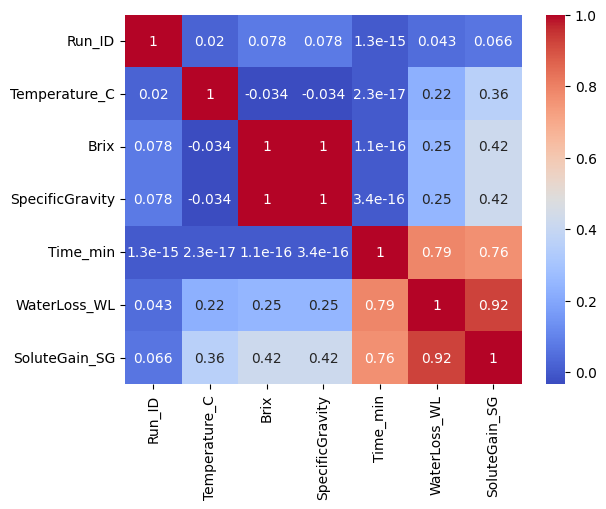

In [12]:
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')

In [13]:

from sklearn.model_selection import GroupKFold
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import ExtraTreesRegressor, RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.multioutput import RegressorChain, MultiOutputRegressor
from sklearn.neural_network import MLPRegressor


df = pd.read_csv('Osmotic_Dehydration.csv')

# (Kinetic Feature Engineering)
df['Temp_K'] = df['Temperature_C'] + 273.15
df['Driving_Force'] = df['Temp_K'] * df['Brix'] # Osmotic pressure scale
df['Sqrt_Time'] = np.sqrt(df['Time_min'])        # Fickian diffusion scale

# SpecificGravity collinearity removing using FE
X = df[['Temperature_C', 'Brix', 'Time_min', 'Driving_Force', 'Sqrt_Time']]
Y = df[['WaterLoss_WL', 'SoluteGain_SG']]
groups = df['Run_ID']

# GroupKFold Cross-Validation (Unseen Runs Generalization)
gkf = GroupKFold(n_splits=5)

# model setup
models = {
    'Multi-Task MLP (ANN)': Pipeline([
        ('scaler', StandardScaler()),
        ('mlp', MLPRegressor(hidden_layer_sizes=(256, 128, 64), activation='relu', max_iter=1000, random_state=42, early_stopping=True))
    ]),
    'Multi-Output Extra Trees': ExtraTreesRegressor(n_estimators=300, max_depth=15, random_state=42),
    'Regressor Chain (HistGBR)': RegressorChain(HistGradientBoostingRegressor(max_iter=300, random_state=42)),
    'Multi-Output Random Forest': RandomForestRegressor(n_estimators=200, random_state=42)
}

# Evaluatin and Perfomance
results = []

for name, model in models.items():
    wl_r2, sg_r2, wl_rmse, sg_rmse, wl_mae, sg_mae = [], [], [], [], [], []
    
    for train_idx, test_idx in gkf.split(X, Y, groups):
        X_tr, X_te = X.iloc[train_idx], X.iloc[test_idx]
        Y_tr, Y_te = Y.iloc[train_idx], Y.iloc[test_idx]
        
        model.fit(X_tr, Y_tr)
        preds = model.predict(X_te)
        
        # Physics Boundary Constraint Enforcement: Ensure WL(0) = 0 and SG(0) = 0
        t_mask = (X_te['Time_min'] == 0).values
        preds[t_mask, :] = 0.0
        
        wl_r2.append(r2_score(Y_te['WaterLoss_WL'], preds[:, 0]))
        sg_r2.append(r2_score(Y_te['SoluteGain_SG'], preds[:, 1]))
        wl_rmse.append(np.sqrt(mean_squared_error(Y_te['WaterLoss_WL'], preds[:, 0])))
        sg_rmse.append(np.sqrt(mean_squared_error(Y_te['SoluteGain_SG'], preds[:, 1])))
        wl_mae.append(mean_absolute_error(Y_te['WaterLoss_WL'], preds[:, 0]))
        sg_mae.append(mean_absolute_error(Y_te['SoluteGain_SG'], preds[:, 1]))
        
    results.append({
        'Model': name,
        'WL R2': np.mean(wl_r2),
        'SG R2': np.mean(sg_r2),
        'WL RMSE (%)': np.mean(wl_rmse),
        'SG RMSE (%)': np.mean(sg_rmse),
        'WL MAE (%)': np.mean(wl_mae),
        'SG MAE (%)': np.mean(sg_mae)
    })

comparison_df = pd.DataFrame(results)
print("=== Q1 RESEARCH BENCHMARK RESULTS (GroupKFold CV) ===")
print(comparison_df.to_string(index=False))

=== Q1 RESEARCH BENCHMARK RESULTS (GroupKFold CV) ===
                     Model    WL R2    SG R2  WL RMSE (%)  SG RMSE (%)  WL MAE (%)  SG MAE (%)
      Multi-Task MLP (ANN) 0.986660 0.988795     2.088193     0.482201    1.607127    0.370719
  Multi-Output Extra Trees 0.985038 0.984363     2.203665     0.561216    1.774119    0.412128
 Regressor Chain (HistGBR) 0.977895 0.976448     2.678322     0.701246    2.072292    0.523098
Multi-Output Random Forest 0.982128 0.976836     2.392966     0.681058    1.874711    0.488848


In [14]:
from scipy.optimize import curve_fit

# Mathematical Formulations
def peleg_model(t, k1, k2):
    return t / (k1 + k2 * t + 1e-8)

def azuara_model(t, k1, y_inf):
    return (k1 * t * y_inf) / (1 + k1 * t + 1e-8)

runs = df['Run_ID'].unique()
peleg_wl_preds, peleg_sg_preds = np.zeros(len(df)), np.zeros(len(df))
azuara_wl_preds, azuara_sg_preds = np.zeros(len(df)), np.zeros(len(df))

for run in runs:
    idx = df[df['Run_ID'] == run].index
    t = df.loc[idx, 'Time_min'].values
    wl = df.loc[idx, 'WaterLoss_WL'].values
    sg = df.loc[idx, 'SoluteGain_SG'].values
    
    # Fit Peleg
    popt_p_wl, _ = curve_fit(peleg_model, t[1:], wl[1:], p0=[1.0, 0.01], bounds=(0, [100, 1]))
    popt_p_sg, _ = curve_fit(peleg_model, t[1:], sg[1:], p0=[10.0, 0.05], bounds=(0, [500, 1]))
    peleg_wl_preds[idx] = peleg_model(t, *popt_p_wl)
    peleg_sg_preds[idx] = peleg_model(t, *popt_p_sg)
    
    # Fit Azuara
    popt_a_wl, _ = curve_fit(azuara_model, t[1:], wl[1:], p0=[0.01, 70.0], bounds=(0, [1, 100]))
    popt_a_sg, _ = curve_fit(azuara_model, t[1:], sg[1:], p0=[0.01, 20.0], bounds=(0, [1, 30]))
    azuara_wl_preds[idx] = azuara_model(t, *popt_a_wl)
    azuara_sg_preds[idx] = azuara_model(t, *popt_a_sg)

print("=== CLASSICAL KINETICS vs PROPOSED ML ===")
print(f"Peleg Model   -> WL R²: {r2_score(df['WaterLoss_WL'], peleg_wl_preds):.4f} | SG R²: {r2_score(df['SoluteGain_SG'], peleg_sg_preds):.4f}")
print(f"Azuara Model  -> WL R²: {r2_score(df['WaterLoss_WL'], azuara_wl_preds):.4f} | SG R²: {r2_score(df['SoluteGain_SG'], azuara_sg_preds):.4f}")

=== CLASSICAL KINETICS vs PROPOSED ML ===
Peleg Model   -> WL R²: 0.9929 | SG R²: 0.9987
Azuara Model  -> WL R²: 0.9929 | SG R²: 0.9987


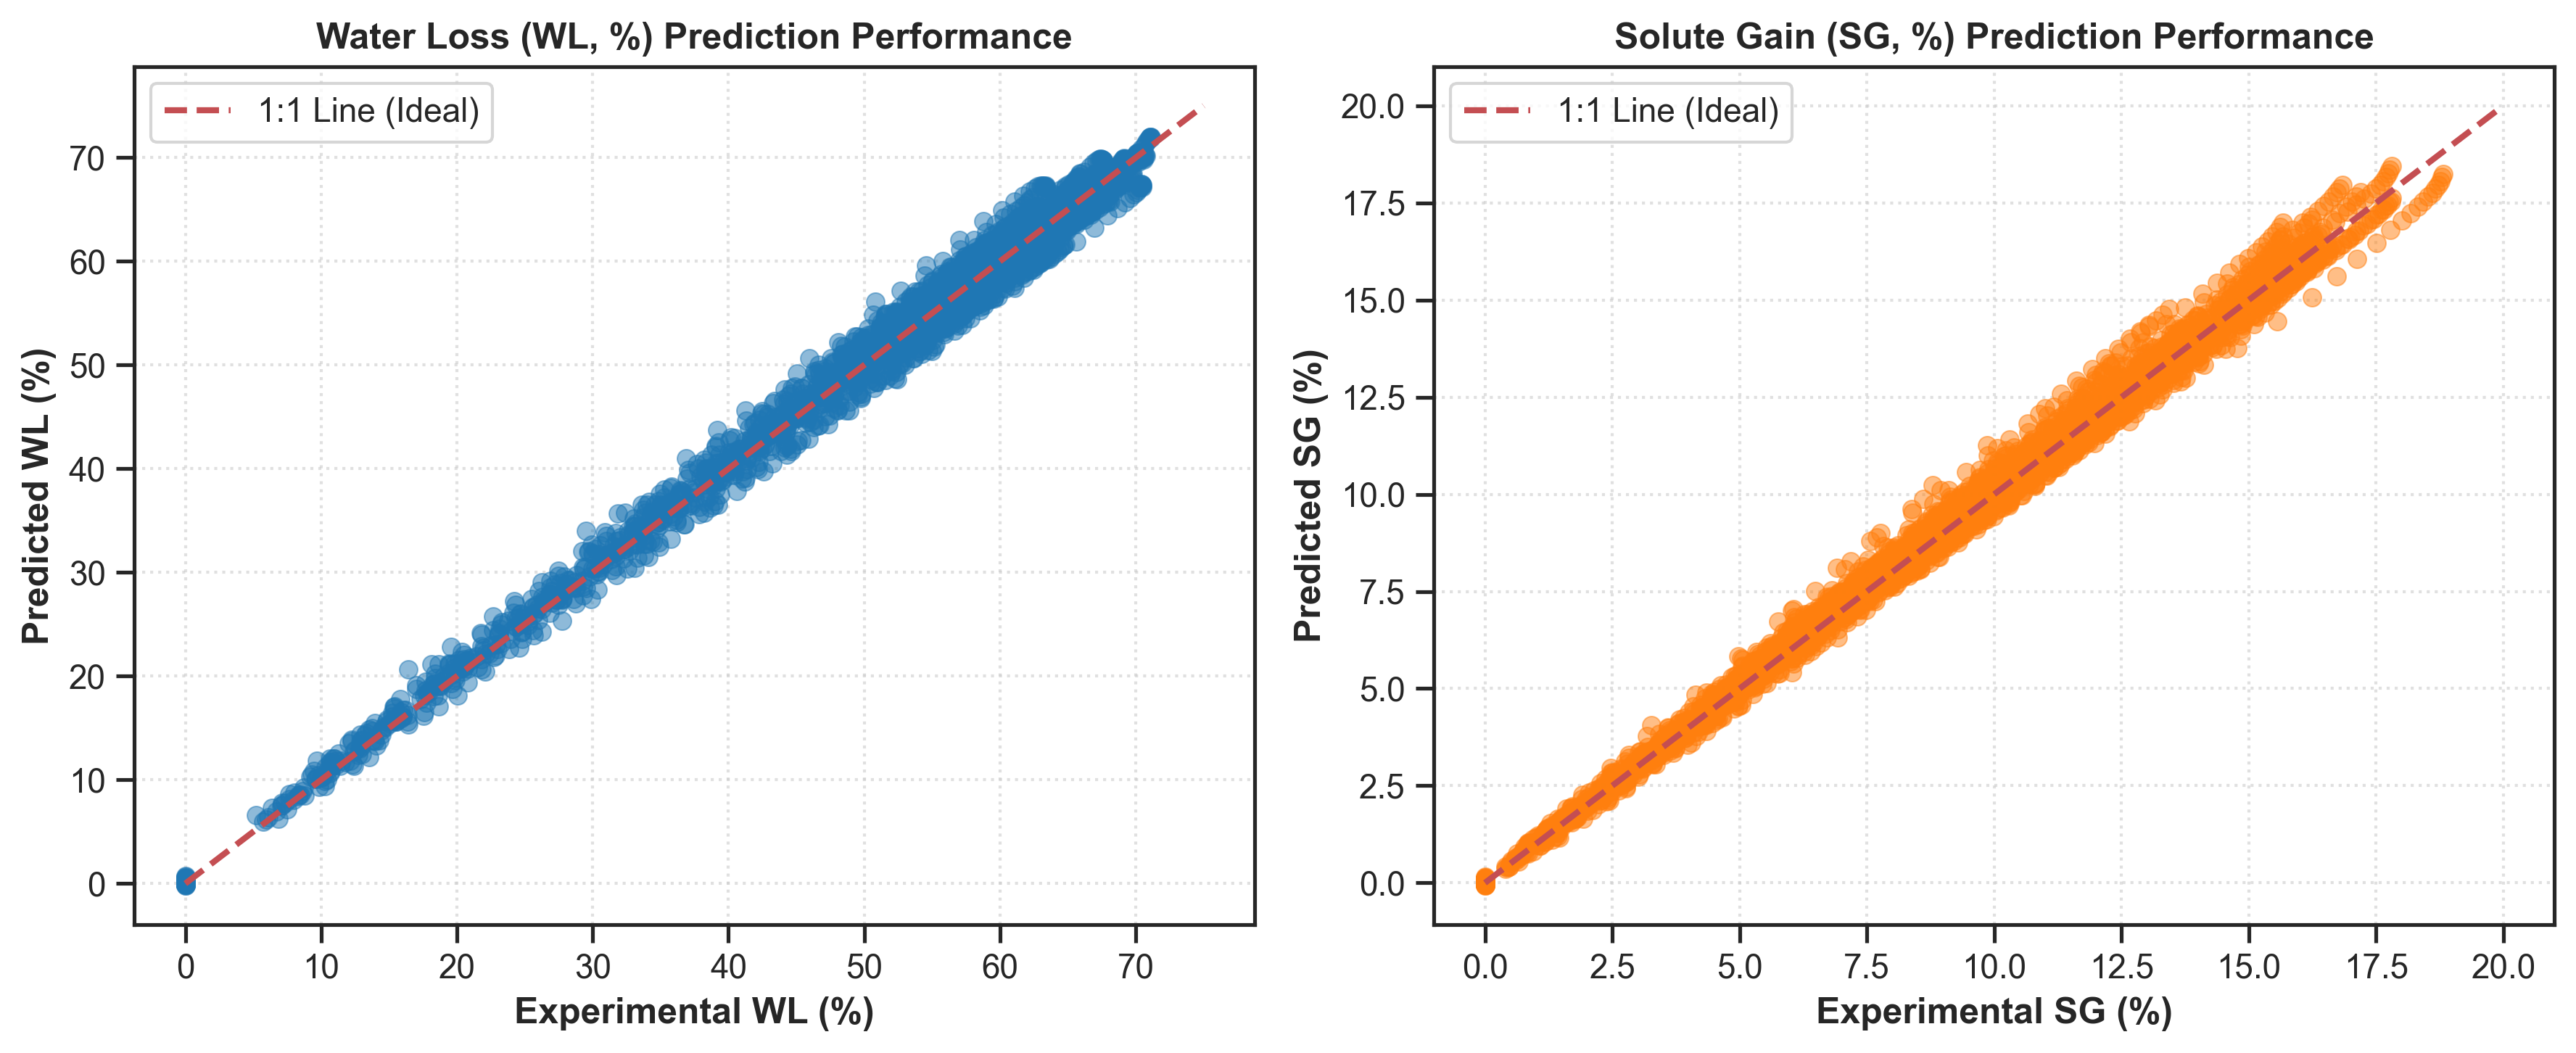

In [16]:
sns.set_theme(style="ticks", font="sans-serif")
fig, axes = plt.subplots(1, 2, figsize=(12, 5), dpi=300)

# Generate cross-validated predictions using Multi-Task MLP
mlp_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('mlp', MLPRegressor(hidden_layer_sizes=(256, 128, 64), max_iter=1000, random_state=42))
])
mlp_pipeline.fit(X, Y)
preds_mlp = mlp_pipeline.predict(X)

# WL Prediction Scatter
sns.scatterplot(x=Y['WaterLoss_WL'], y=preds_mlp[:, 0], ax=axes[0], color='#1f77b4', alpha=0.5, edgecolor=None)
axes[0].plot([0, 75], [0, 75], 'r--', lw=2, label='1:1 Line (Ideal)')
axes[0].set_title('Water Loss (WL, %) Prediction Performance', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Experimental WL (%)', fontweight='bold')
axes[0].set_ylabel('Predicted WL (%)', fontweight='bold')
axes[0].legend(frameon=True)
axes[0].grid(True, linestyle=':', alpha=0.6)

# SG Prediction Scatter
sns.scatterplot(x=Y['SoluteGain_SG'], y=preds_mlp[:, 1], ax=axes[1], color='#ff7f0e', alpha=0.5, edgecolor=None)
axes[1].plot([0, 20], [0, 20], 'r--', lw=2, label='1:1 Line (Ideal)')
axes[1].set_title('Solute Gain (SG, %) Prediction Performance', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Experimental SG (%)', fontweight='bold')
axes[1].set_ylabel('Predicted SG (%)', fontweight='bold')
axes[1].legend(frameon=True)
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
# plt.savefig('Figure_Actual_vs_Predicted_300DPI.png', dpi=300)
plt.show()

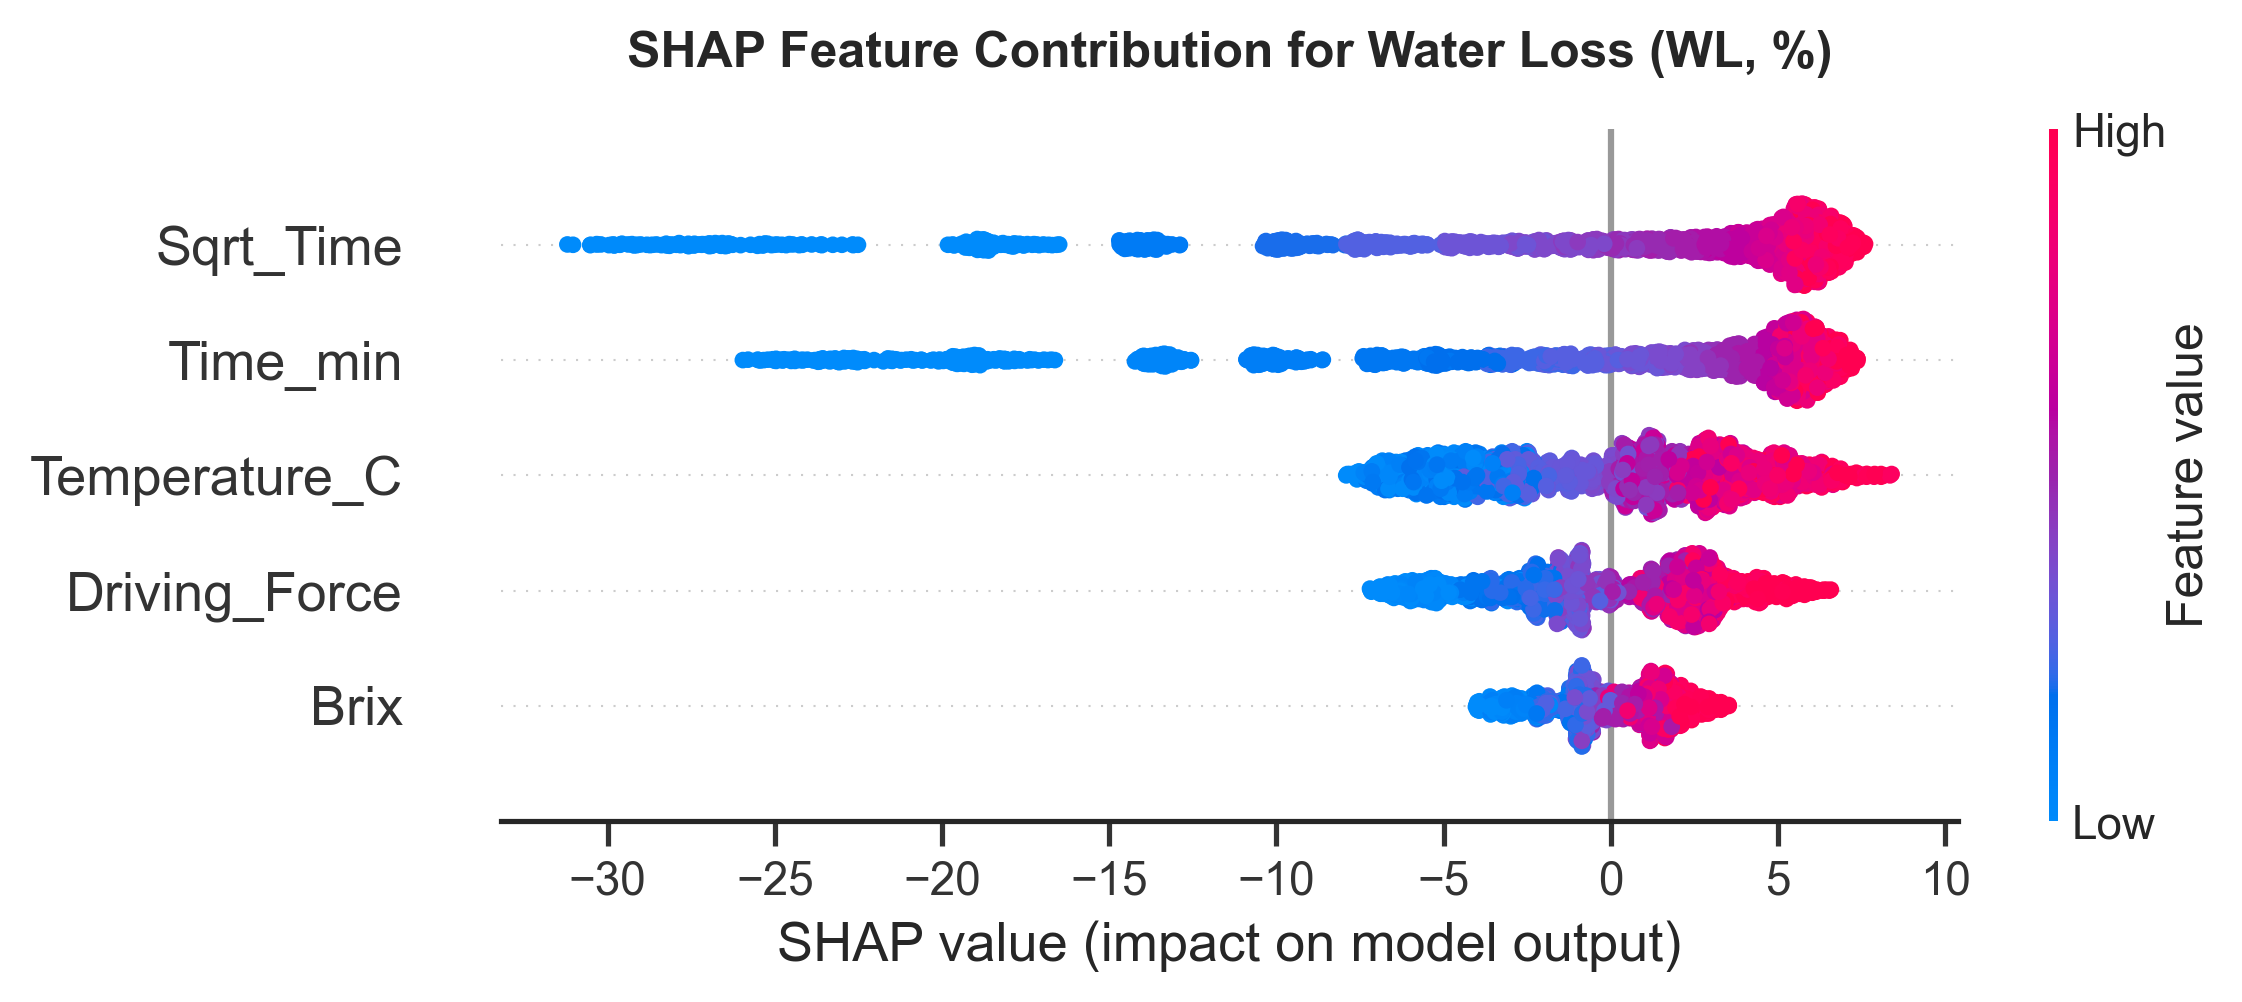

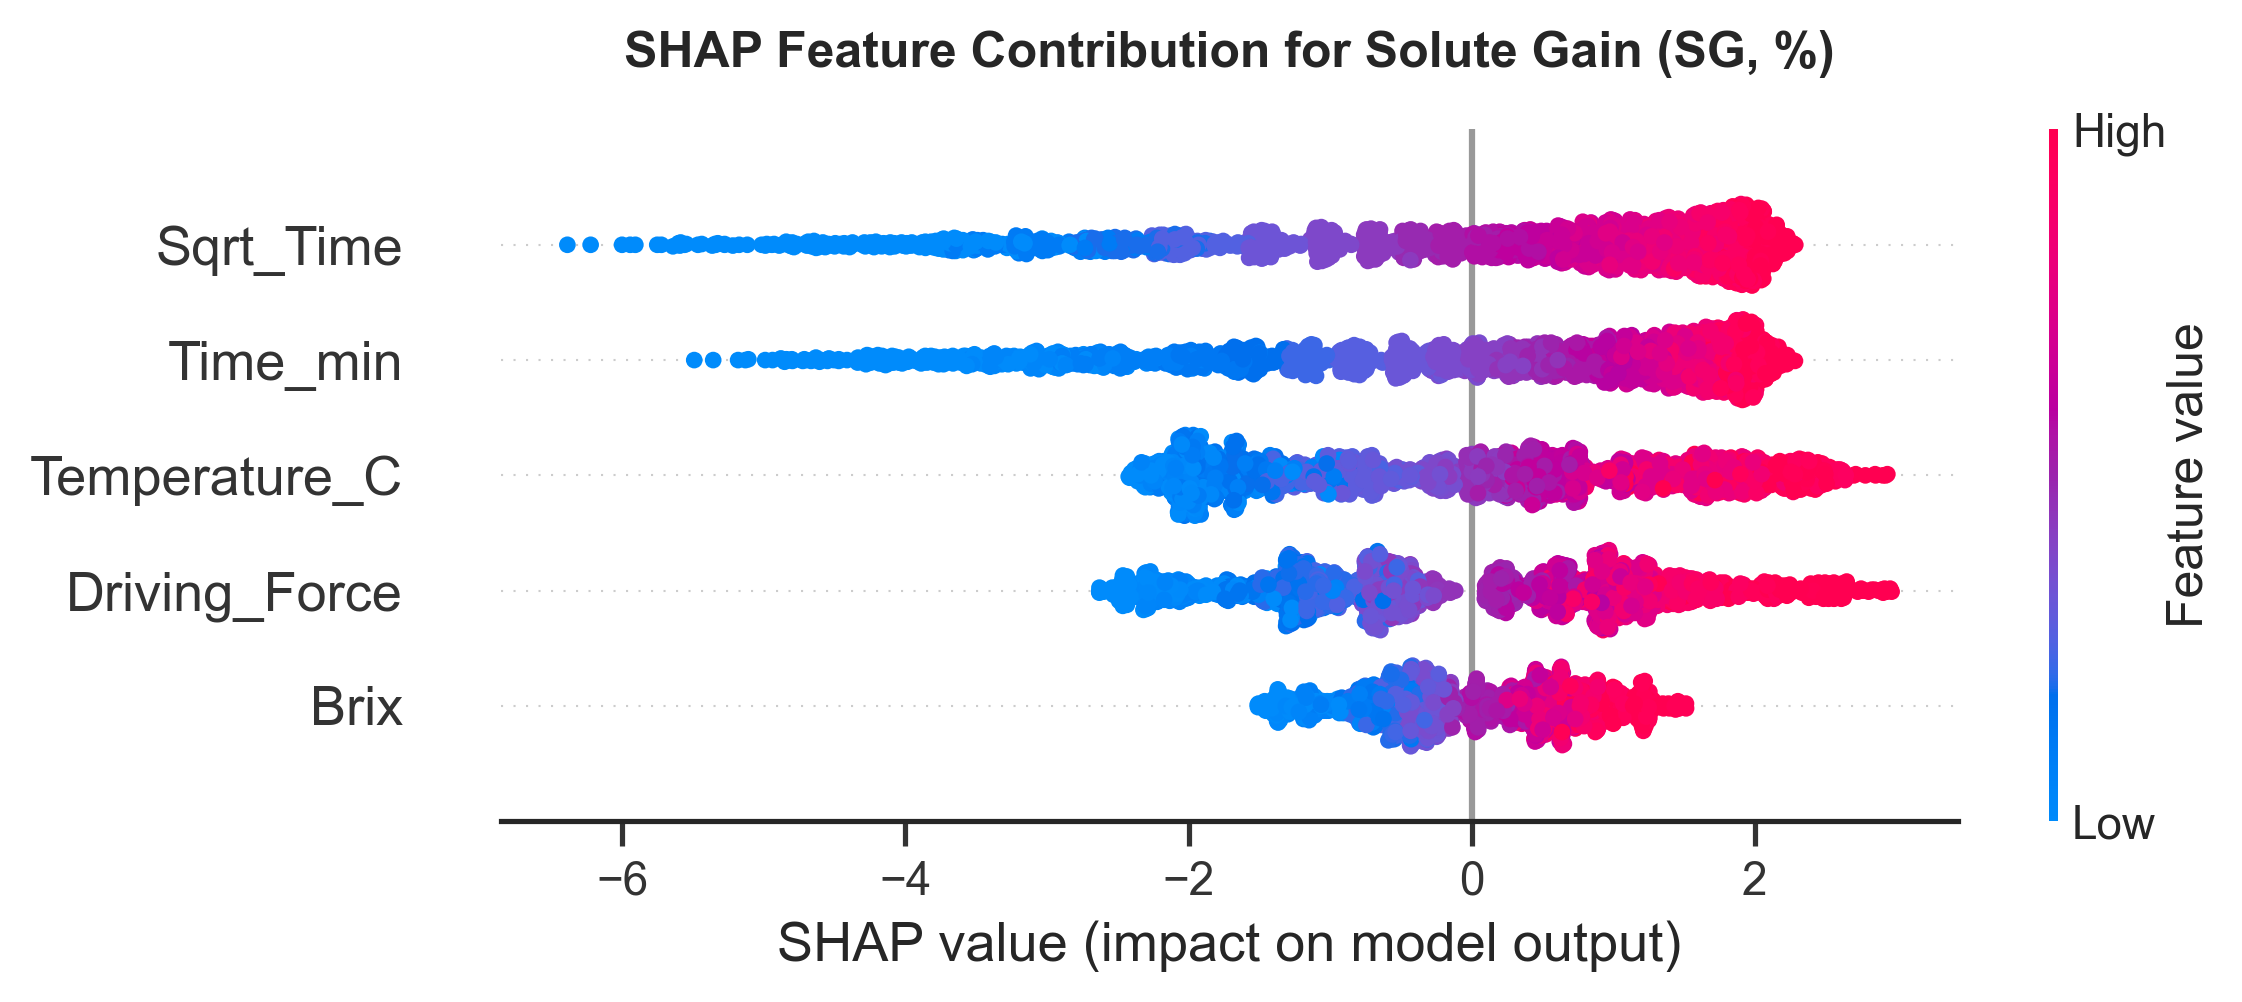

In [17]:
import shap


# 1. Train model on full features
best_model = ExtraTreesRegressor(n_estimators=300, max_depth=15, random_state=42)
best_model.fit(X, Y)

# 2. Compute SHAP values
explainer = shap.TreeExplainer(best_model)
shap_values = explainer(X)  # Modern SHAP API (returns Explanation object)

# Handle both 3D array/Explanation and List formats automatically
if isinstance(shap_values, np.ndarray) and shap_values.ndim == 3:
    # Shape is (n_samples, n_features, n_outputs) -> Slice along output dimension
    shap_wl = shap_values[:, :, 0]
    shap_sg = shap_values[:, :, 1]
elif hasattr(shap_values, 'values') and shap_values.values.ndim == 3:
    # Modern Explanation object with 3D values
    shap_wl = shap_values[:, :, 0]
    shap_sg = shap_values[:, :, 1]
elif isinstance(shap_values, list):
    # Older list of arrays format
    shap_wl = shap_values[0]
    shap_sg = shap_values[1]

# 3. SHAP Summary Plot for Water Loss (WL, %)

plt.figure(figsize=(8, 5), dpi=300)
shap.summary_plot(shap_wl, X, show=False)
plt.title("SHAP Feature Contribution for Water Loss (WL, %)", fontsize=12, fontweight='bold', pad=15)
plt.tight_layout()
# plt.savefig("SHAP_WL_Summary.png", dpi=300)
plt.show()

# 4. SHAP Summary Plot for Solute Gain (SG, %)
plt.figure(figsize=(8, 5), dpi=300)
shap.summary_plot(shap_sg, X, show=False)
plt.title("SHAP Feature Contribution for Solute Gain (SG, %)", fontsize=12, fontweight='bold', pad=15)
plt.tight_layout()
# plt.savefig("SHAP_SG_Summary.png", dpi=300)
plt.show()
